# Exp02：基于前馈神经网络完成鸢尾花分类（Paddle）

在本实践中，我们继续使用第三章中的鸢尾花分类任务，将Softmax分类器替换为本章介绍的前馈神经网络。
在本实践中，我们使用的损失函数为交叉熵损失；优化器为随机梯度下降法；评价指标为准确率。

# 1. 小批量梯度下降法
在梯度下降法中，目标函数是整个训练集上的风险函数，这种方式称为**批量梯度下降法（Batch Gradient Descent，BGD）**。 批量梯度下降法在每次迭代时需要计算每个样本上损失函数的梯度并求和。当训练集中的样本数量$N$很大时，空间复杂度比较高，每次迭代的计算开销也很大。

为了减少每次迭代的计算复杂度，我们可以在每次迭代时只采集一小部分样本，计算在这组样本上损失函数的梯度并更新参数，这种优化方式称为
小批量梯度下降法（Mini-Batch Gradient Descent，Mini-Batch GD）。

第$t$次迭代时，随机选取一个包含$K$个样本的子集$\mathcal{B}_t$，计算这个子集上每个样本损失函数的梯度并进行平均，然后再进行参数更新。
$$
\theta_{t+1} \leftarrow \theta_t  - \alpha \frac{1}{K} \sum_{(\boldsymbol{x},y)\in \mathcal{S}_t} \frac{\partial \mathcal{L}\Big(y,f(\boldsymbol{x};\theta)\Big)}{\partial \theta},
$$
其中$K$为**批量大小(Batch Size)**。$K$通常不会设置很大，一般在$1\sim100$之间。在实际应用中为了提高计算效率，通常设置为2的幂$2^n$。

在实际应用中，小批量随机梯度下降法有收敛快、计算开销小的优点，因此逐渐成为大规模的机器学习中的主要优化算法。
此外，随机梯度下降相当于在批量梯度下降的梯度上引入了随机噪声。在非凸优化问题中，随机梯度下降更容易逃离局部最优点。

小批量随机梯度下降法的训练过程如下：

![](https://ai-studio-static-online.cdn.bcebos.com/49287f7b41234d718fcc79b3f8edc64f366b05f460fb49cea88805777d508d82)


## 1.1 数据分组
为了小批量梯度下降法，我们需要对数据进行随机分组。目前，机器学习中通常做法是构建一个**数据迭代器**，每个迭代过程中从全部数据集中获取一批指定数量的数据。

数据迭代器的实现原理如下图所示：

![](https://ai-studio-static-online.cdn.bcebos.com/337735d2bf6c49dda5415d791f6a320ffe739a809b3541faa26bfb8331506cb3)


1. 首先，将数据集封装为Dataset类，传入一组索引值，根据索引从数据集合中获取数据；
1. 其次，构建DataLoader类，需要指定数据批量的大小和是否需要对数据进行乱序，通过该类即可批量获取数据。

在实践过程中，通常使用进行参数优化。在飞桨中，使用`paddle.io.DataLoader`加载minibatch的数据，
`paddle.io.DataLoader`  API可以生成一个迭代器，其中通过设置`batch_size`参数来指定minibatch的长度，通过设置shuffle参数为True，可以在生成`minibatch`的索引列表时将索引顺序打乱。

参考资料链接：  
使用 paddle.io.Dataset 自定义数据集：https://www.paddlepaddle.org.cn/documentation/docs/zh/guides/beginner/data_load_cn.html  
数据预处理：https://www.paddlepaddle.org.cn/documentation/docs/zh/guides/beginner/data_preprocessing_cn.html

## 1.2 数据处理

Iris数据集，也称为鸢尾花数据集，包含了3种鸢尾花类别（Setosa、Versicolour、Virginica），每种类别有50个样本，共计150个样本。其中每个样本中包含了4个属性：花萼长度、花萼宽度、花瓣长度以及花瓣宽度。

* 鸢尾花属性 </br>
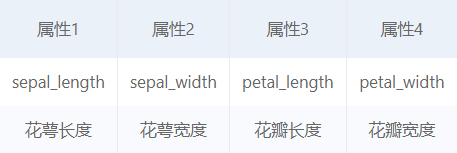
* 鸢尾花类别 </br>
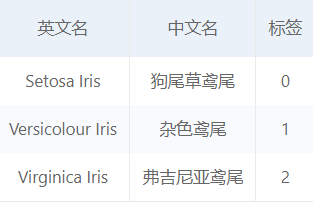

### 1.2.1 自定义加载数据集

In [ ]:
import copy
import paddle
import numpy as np
import paddle.io as io
from sklearn.datasets import load_iris

#加载数据集
def load_data(shuffle=True):
    """
    加载鸢尾花数据
    输入：
        - shuffle：是否打乱数据，数据类型为bool
    输出：
        - X：特征数据，shape=[150,4]
        - y：标签数据, shape=[150,3]
    """
    #加载原始数据
    X = np.array(load_iris().data, dtype=np.float32)
    y = np.array(load_iris().target, dtype=np.int64)

    X = paddle.to_tensor(X)
    y = paddle.to_tensor(y)

    #数据归一化
    X_min = paddle.min(X, axis=0)
    X_max = paddle.max(X, axis=0)
    X = (X-X_min) / (X_max-X_min)

    #如果shuffle为True，随机打乱数据
    if shuffle:
        idx = paddle.randperm(X.shape[0])  # 返回一个数值在0到n-1、随机排列的1-D Tensor
        X_new = copy.deepcopy(X)
        y_new = copy.deepcopy(y)
        for i in range(X.shape[0]):
            X_new[i] = X[idx[i]]
            y_new[i] = y[idx[i]]
        X = X_new
        y = y_new

    return X, y

## 1.2.2 构造IrisDataset类
构造IrisDataset类进行数据读取，继承自`paddle.io.Dataset`类。`paddle.io.Dataset`是用来封装 Dataset的方法和行为的抽象类，通过一个索引获取指定的样本，同时对该样本进行数据处理。当继承`paddle.io.Dataset`来定义数据读取类时，实现如下方法：

* `__getitem__`：根据给定索引获取数据集中指定样本，并对样本进行数据处理；
* `__len__`：返回数据集样本个数。

代码实现如下：


In [ ]:

class IrisDataset(io.Dataset):
    def __init__(self, mode='train', num_train=120, num_dev=15): # iris数据集共150个数据前120个做训练集，121-135做验证集，136-150做测试集
        super(IrisDataset, self).__init__()
        # 调用第三章中的数据读取函数，其中不需要将标签转成one-hot类型
        X, y = load_data(shuffle=True)   # X：特征数据，shape=[150,4]，y：标签数据, shape=[150,3]
        if mode == 'train':
            self.X, self.y = X[:num_train], y[:num_train]
        elif mode == 'dev':
            self.X, self.y = X[num_train:num_train + num_dev], y[num_train:num_train + num_dev]
        else:
            self.X, self.y = X[num_train + num_dev:], y[num_train + num_dev:]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

    def __len__(self):
        return len(self.y)

In [ ]:
# 通过设置固定的种子值，可以确保每次运行代码时，随机数生成器产生的随机数序列是相同的。
# paddle.seed(12)  
train_dataset = IrisDataset(mode='train')
dev_dataset = IrisDataset(mode='dev')
test_dataset = IrisDataset(mode='test')

In [ ]:
# 打印训练集、验证集、测试集长度
print ("length of train set: ", len(train_dataset))
print ("length of dev set: ", len(dev_dataset))
print ("length of test set: ", len(test_dataset))
print("train_dataset[0]:", train_dataset[0])   # 包含数据和标签

### 1.2.3 用DataLoader进行封装

In [ ]:
# 批量大小
batch_size = 16

# 加载数据
train_loader = io.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
dev_loader = io.DataLoader(dev_dataset, batch_size=batch_size)
test_loader = io.DataLoader(test_dataset, batch_size=batch_size)

# 2. 模型构建

构建一个简单的前馈神经网络进行鸢尾花分类实践。其中输入层神经元个数为4，输出层神经元个数为3，隐含层神经元个数为6。代码实现如下：

In [ ]:
from paddle import nn
import paddle.nn.functional as F

# 定义前馈神经网络（方法一）
class Model_MLP_L2_V3(nn.Layer):
    def __init__(self, input_size, output_size, hidden_size):
        super(Model_MLP_L2_V3, self).__init__()
        # 构建第一个全连接层
        self.fc1 = nn.Linear(
            input_size,
            hidden_size,
            weight_attr=paddle.ParamAttr(initializer=nn.initializer.Normal(mean=0.0, std=0.01)),
            bias_attr=paddle.ParamAttr(initializer=nn.initializer.Constant(value=1.0))
        )
        # 构建第二全连接层
        self.fc2 = nn.Linear(
            hidden_size,
            output_size,
            weight_attr=paddle.ParamAttr(initializer=nn.initializer.Normal(mean=0.0, std=0.01)),
            bias_attr=paddle.ParamAttr(initializer=nn.initializer.Constant(value=1.0))
        )
        # 定义网络使用的激活函数
        self.act = nn.Sigmoid()

    def forward(self, inputs):
        outputs = self.fc1(inputs)
        outputs = self.act(outputs)
        outputs = self.fc2(outputs)
        return outputs

# model = Model_MLP_L2_V3(input_size=4, output_size=3, hidden_size=10)

In [ ]:
# 定义前馈神经网络模型（方法二）
class Model_MLP(nn.Layer):
    def __init__(self, input_size, hidden_size, output_size):
        super(Model_MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)  # 输入层到隐藏层
        self.fc2 = nn.Linear(hidden_size, output_size)  # 隐藏层到输出层
        # 定义网络使用的激活函数
        self.act = F.relu   # F.relu、nn.Sigmoid()

    def forward(self, x):
        x = self.act(self.fc1(x))
        x = self.fc2(x)
        return x

# 创建模型实例
model = Model_MLP(input_size=4, hidden_size=10,output_size=3)

# 3. 模型训练


In [ ]:
import paddle.optimizer as opt
import paddle.nn.functional as F

# 设置学习率
lr = 0.2   # 0.01
# 定义损失函数。softmax+交叉熵
loss_fn = F.cross_entropy
# 定义优化器
# optimizer = opt.Adam(parameters=model.parameters(), learning_rate=lr)
optimizer = opt.SGD(learning_rate=lr, parameters=model.parameters())

# 初始化记录列表
train_losses = []        # 记录每训练1个epoch后，模型在整个训练集上的平均损失
train_step_losses = []   # 记录每训练1个step后，模型在该batch训练数据上的平均损失
val_losses = []          # 记录每训练1个step后进行验证时，模型在验证集上的平均损失        
val_accuracies = []      # 记录每训练1个step后进行验证时，模型在验证集上的精度

# 训练模型：使用训练集和验证集进行模型训练，共训练150个epoch。保存准确率最高的模型作为最佳模型。
num_epochs = 150
best_accuracy = 0.0
best_model_state = None
# 模型保存路径
model_path = "best_model.pdparams"

使用训练集和验证集进行模型训练，共训练150个epoch。在实践中，保存准确率最高的模型作为最佳模型。代码实现如下：

In [ ]:
# 每个step（即每个batch）训练后用验证集进行验证并保留最好的
global_step = 0
# 训练总的步数
num_training_steps = num_epochs * len(train_loader)
# 启动训练
for epoch in range(num_epochs):
    # 训练阶段
    model.train()
    train_epoch_loss = 0.0
    for batch_idx, (X_batch, y_batch) in enumerate(train_loader):
        optimizer.clear_grad()
        predictions = model(X_batch)
        train_loss = loss_fn(predictions, y_batch)
        train_step_losses.append(train_loss.item())  # 记录每个step的损失
        train_loss.backward()
        optimizer.step()
        train_epoch_loss += train_loss.item()
        if global_step%100==0:   # 每训练100个step输出一下信息
            print(f"[Train] epoch: {epoch}/{num_epochs}, step: {global_step}/{num_training_steps}, loss: {train_loss.item():.5f}")
        global_step += 1
        
        # 验证阶段
        model.eval()
        val_epoch_loss = 0.0
        correct = 0
        total = 0
        with paddle.no_grad():
            for X_batch, y_batch in dev_loader:
                val_predictions = model(X_batch)
                val_loss = loss_fn(val_predictions, y_batch)
                val_epoch_loss += val_loss.item()
                val_pred_class = paddle.argmax(val_predictions, axis=1)
    #             labels = paddle.squeeze(y_batch, axis=-1)  # 方法一：去掉一个维度
                labels = y_batch.reshape([-1])   # # 方法二：直接展平
                correct += (val_pred_class == labels).sum().item()
                total += len(labels)
                
        # 计算平均验证损失和准确率
        val_epoch_loss /= len(dev_loader)
        val_accuracy = correct / total
        val_losses.append(val_epoch_loss)
        val_accuracies.append(val_accuracy)
        if global_step%50==0:   # 每训练50个step输出一下验证信息 
            print(f"[Evaluate]  val score: {val_accuracy:.5f}, val loss: {val_epoch_loss:.5f}") 

        # 保存最佳模型
        if val_accuracy > best_accuracy:
            best_model_state = model.state_dict()
            print(f"[Evaluate] best accuracy performence has been updated: {best_accuracy:.5f} --> {val_accuracy:.5f}")
            best_accuracy = val_accuracy
            best_model_state = model.state_dict()
            paddle.save(best_model_state, model_path)
        
    
    # 计算平均训练损失
    train_epoch_loss /= len(train_loader)
    train_losses.append(train_epoch_loss)

    

可视化观察训练集损失和训练集loss变化情况。

In [ ]:
import matplotlib.pyplot as plt

# 绘制损失变化曲线
plt.figure(figsize=(10, 5))
# 抽样显示每20个数据点中的第一个数据点
sample_train_losses = train_step_losses[::20]
sample_val_losses = val_losses[::20]
# 对应的step
sample_indices_train = range(0, len(train_step_losses), 20)
sample_indices_val = range(0, len(val_losses), 20)
# 绘制step的曲线
plt.plot(sample_indices_train, sample_train_losses, color="#e4007f", linestyle="-", label='Train Loss')
plt.plot(sample_indices_val, sample_val_losses, color='#f19ec2', linestyle="--", label='Val Loss')
plt.title('Training and Validation Loss Over Steps')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 绘制验证集上的准确率变化曲线
plt.figure(figsize=(10, 5))
# 抽样显示每20个数据点中的第一个数据点
sample_val_accuracies = val_accuracies[::20]
# 对应的epoch或step
sample_indices_val = range(0, len(val_accuracies), 20)
plt.plot(sample_indices_val, sample_val_accuracies, color='#f19ec2', linestyle="--", label='Validation Accuracy')
plt.title('Validation Accuracy Over Steps')
plt.xlabel('Step')
plt.ylabel('Accuracy')
plt.legend()
# 设置Y轴的范围从0到1
plt.ylim(0, 1.2)
plt.show()

从输出结果可以看出准确率随着迭代次数增加逐渐上升，损失函数下降。

# 4. 模型评价

使用测试数据对在训练过程中保存的最佳模型进行评价，观察模型在测试集上的准确率以及Loss情况。代码实现如下：

In [ ]:
import os
# 加载最佳模型
if os.path.exists(model_path):
    model.load_dict(paddle.load(model_path))
    
# 测试模型
model.eval()
test_epoch_loss = 0.0
correct = 0
total = 0
with paddle.no_grad():
    for X_batch, y_batch in test_loader:
        test_predictions = model(X_batch)
        test_loss = loss_fn(test_predictions, y_batch)
        test_epoch_loss += test_loss.item()
        test_pred_class = paddle.argmax(test_predictions, axis=1)
        print("test_pred_class:", test_pred_class)
        labels = y_batch.reshape([-1])   # # 方法二：直接展平
        print("labels:", labels)
        correct += paddle.sum(test_pred_class == labels).item()
        total += len(labels)
    
# 计算平均测试损失和准确率
test_epoch_loss /= len(test_loader)
test_accuracy = correct / total
print(f"Test Accuracy: {test_accuracy:.2f}, Test Loss: {test_epoch_loss:.4f}")

# 5. 模型预测

同样地，也可以使用保存好的模型，对测试集中的某一个数据进行模型预测，观察模型效果。代码实现如下：

In [ ]:
# 获取测试集中第一条数据
X, label = next(test_loader())
logits = model(X)

pred_class = paddle.argmax(logits[0]).numpy()
label = label[0][0].numpy()

# 输出真实类别与预测类别
print("The true category is {} and the predicted category is {}".format(label, pred_class))

# 6. 实践拓展

尝试基于MNIST手写数字识别数据集，设计合适的前馈神经网络进行实践，并取得95%以上的准确率。